In [1]:
import time
import numpy as np

In [2]:
import dask
import dask.array

In [3]:
import h5py
import os
from datetime import datetime

In [4]:
from scipy import ndimage

In [5]:
sample = '024_large_02_3uls'
scan = '0004'
toppath = '/data/visitor/ihmi1620/id19/20261006'

# input paths
procpath = os.path.join(toppath, 'PROCESSED_DATA')
samplepath = os.path.join(procpath, sample, sample+'_'+scan)
int16_volumepath = os.path.join(samplepath, 'reconstructed_volumes','cast_volume')

In [6]:
def load_im_dask(datapath, name, ts=None):
    splitname = name.split('_')
    ts = int(splitname[-3][:-3])
    entry = '/entry'+f'{ts:04d}'+'/reconstruction/results/data'
    tsentry =  '/entry'+f'{ts:04d}'+'/reconstruction/configuration/acquisition/end_time'
    # print(name, entry, tsentry)
    path = os.path.join(datapath, name)
    file = h5py.File(path)
    da = dask.array.from_array(file[entry])
    byte_data = file[tsentry][()]
    timestamp = datetime.fromisoformat(byte_data.decode()).timestamp() # ChatGPT
    return da, timestamp

In [7]:
def stack_4D(datapath):
    names = os.listdir(datapath)
    names.sort()
    data = []
    timestamps = []
    for name in names:
        da, timestamp = load_im_dask(datapath, name)
        data.append(da)
        timestamps.append(timestamp)
    timestamps = np.array(timestamps)
    Stack = dask.array.stack(data, axis=3)
    return Stack, names, timestamps

In [8]:
Stack, names, timestamps = stack_4D(int16_volumepath)

In [19]:
im = Stack[:,:,:,30:45]

In [20]:
im = im.compute()

KeyboardInterrupt: 

In [ ]:
im.shape

In [ ]:
subim = im[1000:1600,200:600,200:600,:]

In [ ]:
# t0 = time.time()
# grad = ndimage.gaussian_filter(subim, 1)
# grad = np.gradient(grad, axis = 2)
# print(time.time()-t0)

In [ ]:
# t0 = time.time()
# grad = ndimage.gaussian_filter(subim, 1, order=(0, 0, 1), mode="nearest")
# print(time.time()-t0)

In [5]:
subim = np.random.rand(500,500,400,40)

In [6]:
volume = dask.array.from_array(subim)
# volume = subim

In [7]:
volume.astype(np.float32)

dask.array<astype, shape=(500, 500, 400, 40), dtype=float32, chunksize=(74, 74, 74, 40), chunktype=numpy.ndarray>

In [8]:
import dask.array as lib
import dask_image.ndfilters

In [9]:
sigma = 1
rho = 3
truncate = 4

In [10]:
volume

dask.array<array, shape=(500, 500, 400, 40), dtype=float64, chunksize=(74, 74, 74, 40), chunktype=numpy.ndarray>

In [11]:
Vx = dask_image.ndfilters.gaussian_filter(volume, sigma, order=(0, 0, 1, 0), mode="nearest", truncate=truncate)  # type: ignore
Vy = dask_image.ndfilters.gaussian_filter(volume, sigma, order=(0, 1, 0, 0), mode="nearest", truncate=truncate)  # type: ignore
Vz = dask_image.ndfilters.gaussian_filter(volume, sigma, order=(1, 0, 0, 0), mode="nearest", truncate=truncate)  # type: ignore  

S = [] # append to list instead of pre-allocate memory, dask takes care of thos

# Integrating elements of structure tensor (scipy uses sequence of 1D).
S.append(lib.multiply(Vx, Vx))
S.append(lib.multiply(Vy, Vy))
S.append(lib.multiply(Vz, Vz))
S.append(lib.multiply(Vx, Vy))
S.append(lib.multiply(Vx, Vz))
S.append(lib.multiply(Vy, Vz))

for i in range(6):
    S[i] = dask_image.ndfilters.gaussian_filter(S[i], [rho, rho, rho, 0], mode="nearest", truncate=truncate)
    
S = lib.stack(S)

In [12]:
S

dask.array<stack, shape=(6, 500, 500, 400, 40), dtype=float64, chunksize=(1, 74, 74, 74, 40), chunktype=numpy.ndarray>

In [2]:
import logging
from typing import Literal

import numpy as np
import numpy.typing as libt
from scipy import ndimage

def eig_special_3d(
    S: libt.ArrayLike,
    full: bool = False,
    eigenvalue_order: Literal["desc", "asc"] = "desc",
) -> tuple[libt.NDArray, libt.NDArray]:
    """Eigensolution for symmetric real 3-by-3 matrices.

    Args:
        S: A floating point array with shape (6, ...) containing structure tensor. Use `float64` to avoid numerical errors. When using lower precision, ensure that the values of S are not very small/large. Pass `cupy.ndarray` to avoid copying S.
        full: A flag indicating that all three eigenvectors should be returned.
        eigenvalue_order: The order of eigenvalues. Either "desc" for descending or "asc" for ascending. If all three eigenvectors are returned, they will be ordered according to the eigenvalues.

    Returns:
        val: An array with shape `(3, ...)` containing eigenvalues.
        vec: An array with shape `(3, ...)` containing the vector corresponding to the smallest eigenvalue if `full` is `False`, otherwise `(3, 3, ...)` containing eigenvectors.

    More:
        An analytic solution of eigenvalue problem for real symmetric matrix,
        using an affine transformation and a trigonometric solution of third
        order polynomial. See https://en.wikipedia.org/wiki/Eigenvalue_algorithm
        which refers to Smith's algorithm https://dl.acm.org/citation.cfm?id=366316.

    Authors: vand@dtu.dk, 2019; niejep@dtu.dk, 2019-2024
    """
    lib = np
    S = lib.asarray(S)

    # Check data type. Must be floating point.
    if not lib.issubdtype(S.dtype, lib.floating):
        raise ValueError("S must be floating point type.")

    # Flatten S.
    input_shape = S.shape
    S = S.reshape(6, -1)

    # Create v vector.
    v = lib.array([[2 * lib.pi / 3], [4 * lib.pi / 3]], dtype=S.dtype)

    # Computing eigenvalues.

    # Allocate vec and val. We will use them for intermediate computations as well.
    if full:
        val = lib.empty((3,) + S.shape[1:], dtype=S.dtype)
        vec = lib.empty((9,) + S.shape[1:], dtype=S.dtype)
        tmp = lib.empty((4,) + S.shape[1:], dtype=S.dtype)
        B03 = val
        B36 = vec[:3]
    else:
        val = lib.empty((3,) + S.shape[1:], dtype=S.dtype)
        vec = lib.empty((3,) + S.shape[1:], dtype=S.dtype)
        tmp = lib.empty((4,) + S.shape[1:], dtype=S.dtype)
        B03 = val
        B36 = vec

    # Views for B.
    B0 = B03[0]
    B1 = B03[1]
    B2 = B03[2]
    B3 = B36[0]
    B4 = B36[1]
    B5 = B36[2]

    # Compute q, mean of diagonal. We need to use q multiple times later.
    # Using lib.mean has precision issues.
    q = lib.add(S[0], S[1], out=tmp[0])
    q += S[2]
    q /= 3

    # Compute S minus q. Insert it directly into B where it'll stay.
    Sq = lib.subtract(S[:3], q, out=B03)

    # Compute s, off-diagonal elements. Store in part of B not yet used.
    s = lib.einsum("ij,ij->j", S[3:], S[3:], out=tmp[1])
    s *= 2

    # Compute p.
    p = lib.einsum("ij,ij->j", Sq, Sq, out=tmp[2])
    del Sq  # Last use of Sq.
    p += s

    p *= 1 / 6
    lib.sqrt(p, out=p)

    # Compute inverse p, while avoiding 0 division.
    # Reuse s allocation and delete s variable.
    p_inv = s
    del s
    p_inv[:] = 0
    lib.divide(1, p, out=p_inv, where=p != 0)

    # Compute B. First part is already filled.
    B03 *= p_inv
    lib.multiply(S[3:], p_inv, out=B36)

    # Compute d, determinant of B.
    d = lib.prod(B03, axis=0, out=tmp[3])

    # Reuse allocation for p_inv and delete variable.
    d_tmp = p_inv
    del p_inv
    # Computation of d.
    lib.multiply(B2, B3, d_tmp)
    d_tmp *= B3
    d -= d_tmp
    lib.multiply(B4, B4, out=d_tmp)
    d_tmp *= B1
    d -= d_tmp
    lib.prod(B36, axis=0, out=d_tmp)
    d_tmp *= 2
    d += d_tmp
    lib.multiply(B5, B5, out=d_tmp)
    d_tmp *= B0
    d -= d_tmp
    d *= 0.5
    # Ensure -1 <= d/2 <= 1.
    lib.clip(d, -1, 1, out=d)

    # Compute phi. Beware that we reuse d variable!
    phi = d
    del d
    phi = lib.arccos(phi, out=phi)
    phi /= 3

    # Compute val, ordered eigenvalues. Resuing B allocation.
    del B03, B36, B0, B1, B2, B3, B4, B5

    lib.add(v, phi[lib.newaxis], out=val[:2])
    val[2] = phi
    lib.cos(val, out=val)
    p *= 2
    val *= p
    val += q

    val = val.reshape(val.shape[:-1] + input_shape[1:])


    return val

In [25]:
def eig_special_3d_robert(S):   
#     #RF: the original code uses quite a few memory allocations incompitble with dask
#     # therfore the eigenvalue extraction is built directly from https://dl.acm.org/doi/epdf/10.1145/355578.366316
#     # testing shows that the built-in numpy (and dask methods) are faster for a single matrix, but full volume much much faster with QIM method
    
    #TODO: maybe only use half of the symmetric matrix as the original code does
    lib =  dask.array
    shp = S.shape
    S = S.reshape(6,-1).astype(lib.float32)
    S0 = S[0]
    S1 = S[1]
    S2 = S[2]
    S3 = S[3]
    S4 = S[4]
    S5 = S[5]
    
    
    # 3m = trace(A)
    m = (S0+S1+S2)/3
    
    
    # 6p = "sum of squares of elements of (A-mI)
    Sq = lib.subtract(S[:3], m)
    s = lib.einsum("ij,ij->j", S[3:], S[3:])
    s *= 2
    p = lib.einsum("ij,ij->j", Sq, Sq)
    p += s
    p /= 6
    
    #2q = det(A - mI)
    S0q = Sq[0]
    S1q = Sq[1]
    S2q = Sq[2]
    
    det = S0q*S1q*S2q + S3*S5*S4 + S4*S3*S5 - S4*S1q*S4 - S3*S3*S2q - S0q*S5*S5
    q = det/2
    
    #phi
    phi = lib.arctan(lib.sqrt(p**3-q**2)/q)/3
    
    #eigenvalues
    psqrt = lib.sqrt(p)
    cos = lib.cos(phi)
    sin = lib.sin(phi)
    
    v1 = m + 2*psqrt*cos
    v2 = m - lib.sqrt(p)*(cos + lib.sqrt(3)*sin)
    v3 = m - lib.sqrt(p)*(cos - lib.sqrt(3)*sin)
    
    val = lib.array([v1,v2,v3])
    val = val.reshape(val.shape[:-1] + shp[1:])

    return val

In [21]:
t0 = time.time()
val_QIM = eig_special_3d(np.float32(S.compute()))
QIM_time = time.time() - t0
print(QIM_time)

5.794294118881226


In [28]:
t0 = time.time()
val_rob = eig_special_3d_robert(S)
val_rob = val_rob[:,:,:,300,20].compute()
rob_time = time.time() - t0
print(rob_time)

/gpfs/gb/data/id19/inhouse/robert/miniforge3/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in sqrt
  return self.func(*new_argspec)
/gpfs/gb/data/id19/inhouse/robert/miniforge3/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)


106.96512484550476


In [29]:
import matplotlib.pyplot as plt

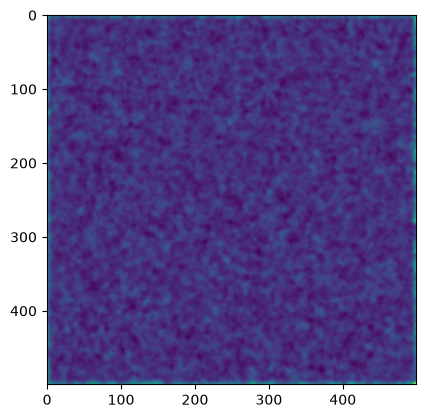

In [32]:
plt.imshow(val_rob.min(axis=0))

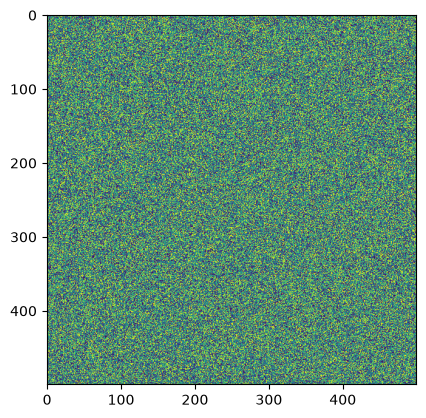

In [34]:
plt.imshow(subim[:,:,300,20])

In [32]:
valmax = val.max(axis=0)

In [33]:
valmax.shape

(600, 400, 400)

In [34]:
import napari
# import numpy as np

viewer = napari.Viewer()

# test = np.random.rand(10,10,10, 10)


In [ ]:
viewer.add_image(valmax)

In [35]:
S

dask.array<stack, shape=(6, 500, 500, 400, 40), dtype=float64, chunksize=(1, 74, 74, 74, 40), chunktype=numpy.ndarray>